<a href="https://colab.research.google.com/github/arailymVinted/blog/blob/main/Copy_of_Lab_1_from_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

data = {
    "patient": ["Name 1", "Name 2", "Name 3", "Name 4", "Name 5", "Name 6", "Name 7", "Name 8", "Name 9", "Name 10", "Name 11", "Name 12", "Name 13", "Name 14", "Name 15", "Name 16"],
    "gender": [0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1],
    "height": [165, 183, 171, 194, 178, 185, 160, 175, 169, 180, np.nan, 182, 167, 190, 163, 177],
    "weight": [55, 95, 60, 102, 80, 90, 52, 78, 63, 85, 54, 92, 58, 98, 54, 77]
}
df = pd.DataFrame(data)
print(df)


    patient  gender  height  weight
0    Name 1       0   165.0      55
1    Name 2       1   183.0      95
2    Name 3       0   171.0      60
3    Name 4       1   194.0     102
4    Name 5       1   178.0      80
5    Name 6       1   185.0      90
6    Name 7       0   160.0      52
7    Name 8       1   175.0      78
8    Name 9       0   169.0      63
9   Name 10       1   180.0      85
10  Name 11       0     NaN      54
11  Name 12       1   182.0      92
12  Name 13       0   167.0      58
13  Name 14       1   190.0      98
14  Name 15       0   163.0      54
15  Name 16       1   177.0      77


# Patient data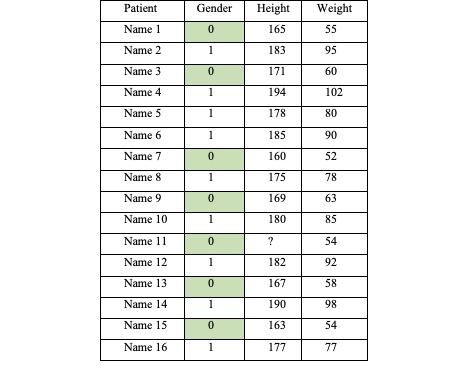

In [ ]:
# guessing woman's height, therefore taking into account only women's height
df_female_data = df[df['gender'] == 0]
print(df_female_data)

df_female_height_data = df_female_data['height']
print(df_female_height_data)




    patient  gender  height  weight
0    Name 1       0   165.0      55
2    Name 3       0   171.0      60
6    Name 7       0   160.0      52
8    Name 9       0   169.0      63
10  Name 11       0     NaN      54
12  Name 13       0   167.0      58
14  Name 15       0   163.0      54
0     165.0
2     171.0
6     160.0
8     169.0
10      NaN
12    167.0
14    163.0
Name: height, dtype: float64


In [ ]:
df_women_height_mean = df_female_height_data.mean()
df_women_height_median = df_female_height_data.median()
print("Mean: " + str(df_women_height_mean))
print("Median: " + str(df_women_height_median))
print()

#impute missing height value
df_impute_mean = df.copy()
df_impute_mean['height'] = df['height'].fillna(df_women_height_mean)
print(df_impute_mean.round(2))

print()
df_impute_median = df.copy()
df_impute_median['height'] = df['height'].fillna(df_women_height_median)
print(df_impute_median.round(2))



Mean: 165.83333333333334
Median: 166.0

    patient  gender  height  weight
0    Name 1       0  165.00      55
1    Name 2       1  183.00      95
2    Name 3       0  171.00      60
3    Name 4       1  194.00     102
4    Name 5       1  178.00      80
5    Name 6       1  185.00      90
6    Name 7       0  160.00      52
7    Name 8       1  175.00      78
8    Name 9       0  169.00      63
9   Name 10       1  180.00      85
10  Name 11       0  165.83      54
11  Name 12       1  182.00      92
12  Name 13       0  167.00      58
13  Name 14       1  190.00      98
14  Name 15       0  163.00      54
15  Name 16       1  177.00      77

    patient  gender  height  weight
0    Name 1       0   165.0      55
1    Name 2       1   183.0      95
2    Name 3       0   171.0      60
3    Name 4       1   194.0     102
4    Name 5       1   178.0      80
5    Name 6       1   185.0      90
6    Name 7       0   160.0      52
7    Name 8       1   175.0      78
8    Name 9       0   1

Conclusion: based on female patients only, the estimated height of patient #11 is 165.83 cm (mean) and 166 cm (median). The mean is almost equal to the median, which suggests there are no strong outliers in the data.

In [ ]:
#task 2
# Find anomalies using Z score, formula is Z = (every array element - mean) / std
participants_age_array = np.array([ 8, 10, 9, 12, 11, 14, 13, 15, 10, 9, 88, 12, 11, 13, 14, 15, 16, 12, 10, 13, 11, 14, 15, 9, 8, 12, 13, 14, 15, 16])
print(participants_age_array)
mean_of_age = np.mean(participants_age_array)
std_of_age = np.std(participants_age_array)
print(mean_of_age)
print(std_of_age)

z_scores_of_each_participants_age = (participants_age_array - mean_of_age)/std_of_age
print(z_scores_of_each_participants_age)

convert_z_score_to_absolute_list = np.abs(z_scores_of_each_participants_age)
print(convert_z_score_to_absolute_list)

# filter out values above 3
anomalies_index_list = np.where(convert_z_score_to_absolute_list > 3)[0]
print(anomalies_index_list)
anomaly_value = participants_age_array[anomalies_index_list]
anomaly_z_score = convert_z_score_to_absolute_list[anomalies_index_list]
print("Anomaly value: " + str(anomaly_value))
print("Anomaly Z score: " + str(anomaly_z_score))

#do calculation without anomaly, to find new anomaly

participants_age_array_without_anomaly = np.delete(participants_age_array, anomalies_index_list)
print("List without anomaly")
print(participants_age_array_without_anomaly)

#same calculation to find new anomaly
mean_of_age_2 = np.mean(participants_age_array_without_anomaly)
std_of_age_2 = np.std(participants_age_array_without_anomaly)
print(mean_of_age_2)
print(std_of_age_2)

z_scores_of_each_participants_age_2 = (participants_age_array_without_anomaly - mean_of_age_2)/std_of_age_2
print(z_scores_of_each_participants_age_2)

convert_z_score_to_absolute_list_2 = np.abs(z_scores_of_each_participants_age_2)
print(convert_z_score_to_absolute_list_2)

# filter out values above 3
anomalies_index_list_2 = np.where(convert_z_score_to_absolute_list_2 > 3)[0]

if (anomalies_index_list_2.size == 0):
    print("No anomalies detected")

else:
  print(anomalies_index_list_2)







[ 8 10  9 12 11 14 13 15 10  9 88 12 11 13 14 15 16 12 10 13 11 14 15  9
  8 12 13 14 15 16]
14.733333333333333
13.800805129492346
[-0.48789424 -0.34297516 -0.4154347  -0.19805608 -0.27051562 -0.053137
 -0.12559654  0.01932254 -0.34297516 -0.4154347   5.30886901 -0.19805608
 -0.27051562 -0.12559654 -0.053137    0.01932254  0.09178208 -0.19805608
 -0.34297516 -0.12559654 -0.27051562 -0.053137    0.01932254 -0.4154347
 -0.48789424 -0.19805608 -0.12559654 -0.053137    0.01932254  0.09178208]
[0.48789424 0.34297516 0.4154347  0.19805608 0.27051562 0.053137
 0.12559654 0.01932254 0.34297516 0.4154347  5.30886901 0.19805608
 0.27051562 0.12559654 0.053137   0.01932254 0.09178208 0.19805608
 0.34297516 0.12559654 0.27051562 0.053137   0.01932254 0.4154347
 0.48789424 0.19805608 0.12559654 0.053137   0.01932254 0.09178208]
[10]
Anomaly value: [88]
Anomaly Z score: [5.30886901]
List without anomaly
[ 8 10  9 12 11 14 13 15 10  9 12 11 13 14 15 16 12 10 13 11 14 15  9  8
 12 13 14 15 16]
12.2068

In [ ]:
#task 3 Anomaly detection using Chauvenet’s criterion.
from scipy.special import erfc
participants_age_array = np.array([ 8, 10, 9, 12, 11, 14, 13, 15, 10, 9, 88, 12, 11, 13, 14, 15, 16, 12, 10, 13, 11, 14, 15, 9, 8, 12, 13, 14, 15, 16])

# If that value is smaller than the limit 1/(2n), it’s an anomaly.


#more concise answer

def chauvent(data):
  ages = np.array(data)
  iteration = 1
  while True: # loop breaks when no any anomaly is detected in a list
    n = ages.size
    mean = np.mean(ages)
    std = np.std(ages, ddof=1)
    limit = 1 / (2 * n)

    #true/false (boolean) array list
    # np.abs apply this formula to every element separetly
    is_anomaly = erfc(np.abs(ages-mean)/std) < limit

    print(f"Iteration {iteration}: n={n}, mean={mean:.2f}, std={std:.2f}, "
                f"limit={limit:.4f}, anomalies={ages[is_anomaly]}")

    if not is_anomaly.any():        # If there are no anomalies → exit the function and return list of array
      return ages
    ages = ages[~is_anomaly]        # remove anomalies, repeat (~is_anomaly means to form array without anomaly)
    iteration += 1

array_without_anomalies = chauvent (participants_age_array)
print("Array without anomalies: ")
print(f"Array without anomaly {array_without_anomalies}")




Iteration 1: n=30, mean=14.73, std=14.04, limit=0.0167, anomalies=[88]
Iteration 2: n=29, mean=12.21, std=2.40, limit=0.0172, anomalies=[8 8]
Iteration 3: n=27, mean=12.52, std=2.17, limit=0.0185, anomalies=[]
Array without anomalies: 
Array without anomaly [10  9 12 11 14 13 15 10  9 12 11 13 14 15 16 12 10 13 11 14 15  9 12 13
 14 15 16]


In [ ]:
#Task 4 Quartile algorithm

#q1 = 25% of sample is below it
#q2 = 50% of sample is below it
#q3 = 75% of sample is below it

#If the value is outside this interval it's considered outlier/anomaly
# [(q1 - 1.5 * (q3 - q1),  q3 + 1.5 * (q3 - q1)]
participants_age_array = np.array([ 8, 10, 9, 12, 11, 14, 13, 15, 10, 9, 88, 12, 11, 13, 14, 15, 16, 12, 10, 13, 11, 14, 15, 9, 8, 12, 13, 14, 15, 16])
quartiles = np.quantile (participants_age_array, [0.25, 0.5, 0.75])

print(quartiles)

q1 = quartiles[0]
q2 = quartiles[1]
q3 = quartiles[2]

print(q1, q2, q3)
lower_limit = q1 - (1.5 * (q3 - q1))
upper_limit = q3 + (1.5 * (q3 - q1))

print(f"Interval [{lower_limit} and {upper_limit}]")

array_without_anomaly_q = []
for value in participants_age_array:
  if value < lower_limit or value > upper_limit:
    print(f"{value} is an anomaly")
  else:
    array_without_anomaly_q.append(value)

array_without_anomaly_q = np.array(array_without_anomaly_q)
print(f"Array without anomaly {array_without_anomaly_q}")


[10.25 12.5  14.  ]
10.25 12.5 14.0
Interval [4.625 and 19.625]
88 is an anomaly
Array without anomaly [ 8 10  9 12 11 14 13 15 10  9 12 11 13 14 15 16 12 10 13 11 14 15  9  8
 12 13 14 15 16]


In [ ]:
#Task 5

"""
Task 5. Gender value reconstruction with an artificial neural network.

Network: 2 inputs (height, weight) + bias -> 2 hidden neurons (sigmoid) + bias -> 1 output (sigmoid)
Training: backpropagation, stochastic gradient descent, MSE loss.
Bias: a constant input equal to 1 is fed into every neuron; its weight is learned.
Weights: initialised randomly. Data: min-max normalised to [0, 1].
Based on https://victorzhou.com/blog/intro-to-neural-networks/
"""
import numpy as np

# ---------------- Data (Table 2) ----------------
# name, gender (None = unknown), height, weight
DATA = [
    ("Name 1", 0, 165, 55), ("Name 2", 1, 183, 95), ("Name 3", 0, 171, 60),
    ("Name 4", 1, 194, 102), ("Name 5", None, 158, 54), ("Name 6", 1, 185, 90),
    ("Name 7", 0, 160, 52), ("Name 8", 1, 175, 78), ("Name 9", 0, 169, 63),
    ("Name 10", 1, 180, 85), ("Name 11", 0, 164, 52), ("Name 12", 1, 182, 92),
    ("Name 13", 0, 167, 58), ("Name 14", 1, 190, 98), ("Name 15", 0, 163, 54),
    ("Name 16", 1, 177, 77),
]

BIAS = 1.0


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def deriv_sigmoid_from_output(s):
    # derivative of sigmoid expressed through its output s = sigmoid(x)
    return s * (1.0 - s)


def min_max(column):
    lo, hi = column.min(), column.max()
    return (column - lo) / (hi - lo)


class NeuralNetwork:
    """2-2-1 network. Each weight row has 3 entries: [w_height, w_weight, w_bias]."""

    def __init__(self, rng):
        self.w_h1 = rng.uniform(-1, 1, 3)   # hidden neuron h1
        self.w_h2 = rng.uniform(-1, 1, 3)   # hidden neuron h2
        self.w_o1 = rng.uniform(-1, 1, 3)   # output neuron: [w_h1, w_h2, w_bias]

    def feedforward(self, x):
        xb = np.array([x[0], x[1], BIAS])
        h1 = sigmoid(self.w_h1 @ xb)
        h2 = sigmoid(self.w_h2 @ xb)
        o1 = sigmoid(self.w_o1 @ np.array([h1, h2, BIAS]))
        return h1, h2, o1

    def train(self, X, y, learn_rate, epochs):
        for _ in range(epochs):
            for x, y_true in zip(X, y):
                xb = np.array([x[0], x[1], BIAS])
                h1, h2, o1 = self.feedforward(x)
                hb = np.array([h1, h2, BIAS])

                # --- backpropagation (loss = (y_true - o1)^2) ---
                dL_do1 = -2.0 * (y_true - o1)
                delta_o = dL_do1 * deriv_sigmoid_from_output(o1)

                delta_h1 = delta_o * self.w_o1[0] * deriv_sigmoid_from_output(h1)
                delta_h2 = delta_o * self.w_o1[1] * deriv_sigmoid_from_output(h2)

                # --- weight update ---
                self.w_o1 -= learn_rate * delta_o * hb
                self.w_h1 -= learn_rate * delta_h1 * xb
                self.w_h2 -= learn_rate * delta_h2 * xb

    def predict(self, X):
        return np.array([self.feedforward(x)[2] for x in X])


def main():
    heights = np.array([r[2] for r in DATA], dtype=float)
    weights = np.array([r[3] for r in DATA], dtype=float)
    X_all = np.column_stack([min_max(heights), min_max(weights)])

    known = [i for i, r in enumerate(DATA) if r[1] is not None]
    unknown = [i for i, r in enumerate(DATA) if r[1] is None][0]   # patient 5
    X_train = X_all[known]
    y_train = np.array([DATA[i][1] for i in known], dtype=float)
    x5 = X_all[unknown]

    print("Normalised data (height, weight):")
    for i, r in enumerate(DATA):
        g = "?" if r[1] is None else r[1]
        print(f"  {r[0]:8s} gender={g}  h={X_all[i,0]:.3f}  w={X_all[i,1]:.3f}")
    print()

    runs = [  # (learning rate, epochs)
        (0.01, 100), (0.01, 1000),
        (0.1, 100), (0.1, 1000),
        (0.5, 500), (0.5, 2000),
        (1.0, 1000), (1.0, 5000),
    ]

    seed = 42
    header = f"{'Run':>3} | {'LR':>5} | {'Epochs':>6} | {'Train MSE':>9} | {'Train acc':>9} | {'P5 output':>9} | {'P5 gender':>9}"
    print("Comparison table (same random initial weights, seed = %d)" % seed)
    print(header)
    print("-" * len(header))
    for n, (lr, ep) in enumerate(runs, 1):
        net = NeuralNetwork(np.random.default_rng(seed))
        net.train(X_train, y_train, lr, ep)
        y_pred = net.predict(X_train)
        mse = np.mean((y_train - y_pred) ** 2)
        acc = np.mean((y_pred >= 0.5) == y_train) * 100
        o5 = net.feedforward(x5)[2]
        g5 = "1 (male)" if o5 >= 0.5 else "0 (female)"
        print(f"{n:>3} | {lr:>5} | {ep:>6} | {mse:>9.5f} | {acc:>8.1f}% | {o5:>9.4f} | {g5:>9}")


if __name__ == "__main__":
    main()


Normalised data (height, weight):
  Name 1   gender=0  h=0.194  w=0.060
  Name 2   gender=1  h=0.694  w=0.860
  Name 3   gender=0  h=0.361  w=0.160
  Name 4   gender=1  h=1.000  w=1.000
  Name 5   gender=?  h=0.000  w=0.040
  Name 6   gender=1  h=0.750  w=0.760
  Name 7   gender=0  h=0.056  w=0.000
  Name 8   gender=1  h=0.472  w=0.520
  Name 9   gender=0  h=0.306  w=0.220
  Name 10  gender=1  h=0.611  w=0.660
  Name 11  gender=0  h=0.167  w=0.000
  Name 12  gender=1  h=0.667  w=0.800
  Name 13  gender=0  h=0.250  w=0.120
  Name 14  gender=1  h=0.889  w=0.920
  Name 15  gender=0  h=0.139  w=0.040
  Name 16  gender=1  h=0.528  w=0.500

Comparison table (same random initial weights, seed = 42)
Run |    LR | Epochs | Train MSE | Train acc | P5 output | P5 gender
--------------------------------------------------------------------
  1 |  0.01 |    100 |   0.24612 |     53.3% |    0.5258 |  1 (male)
  2 |  0.01 |   1000 |   0.11754 |    100.0% |    0.3029 | 0 (female)
  3 |   0.1 |    100 |

In [ ]:
#Task 5
import numpy as np

def sigmoid(x):
  # Sigmoid activation function: f(x) = 1 / (1 + e^(-x))
  return 1 / (1 + np.exp(-x))

def deriv_sigmoid(x):
  # Derivative of sigmoid: f'(x) = f(x) * (1 - f(x))
  fx = sigmoid(x)
  return fx * (1 - fx)

def mse_loss(y_true, y_pred):
  # y_true and y_pred are numpy arrays of the same length.
  return ((y_true - y_pred) ** 2).mean()

def min_max_fit(data):
  # Find the min and max of each column (column 0 = height, column 1 = weight)
  return data.min(axis=0), data.max(axis=0)

def min_max_transform(data, mins, maxs):
  # Scale each value to [0, 1]: (value - min) / (max - min)
  return (data - mins) / (maxs - mins)

class OurNeuralNetwork:
  '''
  A neural network with:
    - 2 inputs (height, weight)
    - a hidden layer with 2 neurons (h1, h2)
    - an output layer with 1 neuron (o1)
  '''
  def __init__(self):
    # Weights (random initialization)
    self.w1 = np.random.normal()
    self.w2 = np.random.normal()
    self.w3 = np.random.normal()
    self.w4 = np.random.normal()
    self.w5 = np.random.normal()
    self.w6 = np.random.normal()

    # Biases
    self.b1 = np.random.normal()
    self.b2 = np.random.normal()
    self.b3 = np.random.normal()

  def feedforward(self, x):
    # x is a numpy array with 2 elements.
    h1 = sigmoid(self.w1 * x[0] + self.w2 * x[1] + self.b1)
    h2 = sigmoid(self.w3 * x[0] + self.w4 * x[1] + self.b2)
    o1 = sigmoid(self.w5 * h1 + self.w6 * h2 + self.b3)
    return o1

  def train(self, data, all_y_trues, learn_rate=0.1, epochs=1000):
    '''
    - data is a (n x 2) numpy array, n = # of samples in the dataset.
    - all_y_trues is a numpy array with n elements.
    - learn_rate: step size for gradient descent
    - epochs: number of times to loop through the entire dataset
    '''
    for epoch in range(epochs):
      for x, y_true in zip(data, all_y_trues):
        # --- Feedforward
        sum_h1 = self.w1 * x[0] + self.w2 * x[1] + self.b1
        h1 = sigmoid(sum_h1)

        sum_h2 = self.w3 * x[0] + self.w4 * x[1] + self.b2
        h2 = sigmoid(sum_h2)

        sum_o1 = self.w5 * h1 + self.w6 * h2 + self.b3
        o1 = sigmoid(sum_o1)
        y_pred = o1

        # --- Partial derivatives (d_L_d_w1 = "partial L / partial w1")
        d_L_d_ypred = -2 * (y_true - y_pred)

        # Neuron o1
        d_ypred_d_w5 = h1 * deriv_sigmoid(sum_o1)
        d_ypred_d_w6 = h2 * deriv_sigmoid(sum_o1)
        d_ypred_d_b3 = deriv_sigmoid(sum_o1)

        d_ypred_d_h1 = self.w5 * deriv_sigmoid(sum_o1)
        d_ypred_d_h2 = self.w6 * deriv_sigmoid(sum_o1)

        # Neuron h1
        d_h1_d_w1 = x[0] * deriv_sigmoid(sum_h1)
        d_h1_d_w2 = x[1] * deriv_sigmoid(sum_h1)
        d_h1_d_b1 = deriv_sigmoid(sum_h1)

        # Neuron h2
        d_h2_d_w3 = x[0] * deriv_sigmoid(sum_h2)
        d_h2_d_w4 = x[1] * deriv_sigmoid(sum_h2)
        d_h2_d_b2 = deriv_sigmoid(sum_h2)

        # --- Update weights and biases (gradient descent)
        # Neuron h1
        self.w1 -= learn_rate * d_L_d_ypred * d_ypred_d_h1 * d_h1_d_w1
        self.w2 -= learn_rate * d_L_d_ypred * d_ypred_d_h1 * d_h1_d_w2
        self.b1 -= learn_rate * d_L_d_ypred * d_ypred_d_h1 * d_h1_d_b1

        # Neuron h2
        self.w3 -= learn_rate * d_L_d_ypred * d_ypred_d_h2 * d_h2_d_w3
        self.w4 -= learn_rate * d_L_d_ypred * d_ypred_d_h2 * d_h2_d_w4
        self.b2 -= learn_rate * d_L_d_ypred * d_ypred_d_h2 * d_h2_d_b2

        # Neuron o1
        self.w5 -= learn_rate * d_L_d_ypred * d_ypred_d_w5
        self.w6 -= learn_rate * d_L_d_ypred * d_ypred_d_w6
        self.b3 -= learn_rate * d_L_d_ypred * d_ypred_d_b3

      # --- Total loss every 10 epochs
      if epoch % 10 == 0:
        y_preds = np.apply_along_axis(self.feedforward, 1, data)
        loss = mse_loss(all_y_trues, y_preds)
        print("Epoch %d loss: %.3f" % (epoch, loss))

# --- Training data: 15 patients (Name 5 excluded – no gender label)
#     columns: [height, weight]
raw_data = np.array([
  [165, 55],   # Name 1
  [183, 95],   # Name 2
  [171, 60],   # Name 3
  [194, 102],  # Name 4
  [185, 90],   # Name 6
  [160, 52],   # Name 7
  [175, 78],   # Name 8
  [169, 63],   # Name 9
  [180, 85],   # Name 10
  [164, 52],   # Name 11
  [182, 92],   # Name 12
  [167, 58],   # Name 13
  [190, 98],   # Name 14
  [163, 54],   # Name 15
  [177, 77],   # Name 16
], dtype=float)

all_y_trues = np.array([0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1])  # 0 = female, 1 = male

# --- Min-max normalization (fit on training data only)
mins, maxs = min_max_fit(raw_data)
data = min_max_transform(raw_data, mins, maxs)

# --- Train
network = OurNeuralNetwork()
network.train(data, all_y_trues, learn_rate=0.1, epochs=1000)

# --- Predict Name 5 (scaled with the SAME mins and maxs)
name5 = min_max_transform(np.array([158, 54], dtype=float), mins, maxs)
pred = network.feedforward(name5)
print("Name 5 normalized input:", name5)
print("Name 5 prediction: %.3f" % pred, "→", "male" if pred >= 0.5 else "female")

Epoch 0 loss: 0.369
Epoch 10 loss: 0.194
Epoch 20 loss: 0.172
Epoch 30 loss: 0.147
Epoch 40 loss: 0.122
Epoch 50 loss: 0.100
Epoch 60 loss: 0.083
Epoch 70 loss: 0.069
Epoch 80 loss: 0.058
Epoch 90 loss: 0.050
Epoch 100 loss: 0.043
Epoch 110 loss: 0.038
Epoch 120 loss: 0.034
Epoch 130 loss: 0.030
Epoch 140 loss: 0.027
Epoch 150 loss: 0.025
Epoch 160 loss: 0.023
Epoch 170 loss: 0.021
Epoch 180 loss: 0.019
Epoch 190 loss: 0.018
Epoch 200 loss: 0.017
Epoch 210 loss: 0.016
Epoch 220 loss: 0.015
Epoch 230 loss: 0.014
Epoch 240 loss: 0.013
Epoch 250 loss: 0.012
Epoch 260 loss: 0.012
Epoch 270 loss: 0.011
Epoch 280 loss: 0.011
Epoch 290 loss: 0.010
Epoch 300 loss: 0.010
Epoch 310 loss: 0.009
Epoch 320 loss: 0.009
Epoch 330 loss: 0.008
Epoch 340 loss: 0.008
Epoch 350 loss: 0.008
Epoch 360 loss: 0.007
Epoch 370 loss: 0.007
Epoch 380 loss: 0.007
Epoch 390 loss: 0.007
Epoch 400 loss: 0.006
Epoch 410 loss: 0.006
Epoch 420 loss: 0.006
Epoch 430 loss: 0.006
Epoch 440 loss: 0.006
Epoch 450 loss: 0.006